In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv("sample_preprocessing_dirty_data.csv")

In [4]:
df

,OrderID,CustomerName,Product,OrderDate,Quantity,UnitPrice,ShippingFee
0,O1001,alice johnson,desk lamp,2026-01-03,2,25.50,4.99
1,O1002,BOB SMITH,office chair,2026-01-04,1,145.00,12.00
2,O1003,Chandra Rao,notebook set,2026-01-05,5,6.50,3.50
3,O1004,deepa kumar,monitor stand,2026-01-06,2,32.00,5.00
4,O1005,Ethan Lee,desk lamp,2026-01-07,3,25.50,4.99
5,O1006,Fatima Noor,office chair,2026-01-08,2,145.00,12.00
6,O1007,Gopal Das,keyboard,not-a-date,1,49.99,4.50
7,O1008,Hana Patel,mouse,2026-01-10,two,18.00,3.00
8,O1009,Ivan Chen,monitor,2026-01-11,1,899.00,20.00
9,O1010,Jaya Reddy,notebook set,2026-01-12,4,NaN,3.50


In [6]:
df.head()

,OrderID,CustomerName,Product,OrderDate,Quantity,UnitPrice,ShippingFee
0,O1001,alice johnson,desk lamp,2026-01-03,2,25.5,4.99
1,O1002,BOB SMITH,office chair,2026-01-04,1,145.0,12.00
2,O1003,Chandra Rao,notebook set,2026-01-05,5,6.5,3.50
3,O1004,deepa kumar,monitor stand,2026-01-06,2,32.0,5.00
4,O1005,Ethan Lee,desk lamp,2026-01-07,3,25.5,4.99


In [7]:
df.tail()

,OrderID,CustomerName,Product,OrderDate,Quantity,UnitPrice,ShippingFee
15,O1015,Omar Khan,premium monitor,2026-01-17,1,12500.0,25.00
16,O1016,Priya Menon,mouse,2026-01-18,3,-18.0,3.00
17,O1017,Quinn Roy,desk lamp,2026-01-19,0,25.5,4.99
18,O1018,Ravi Nair,office chair,2026-01-20,2,145.0,12.00
19,O1019,Sara Ali,notebook set,2026-01-21,1,6.5,3.50


In [8]:
print("Shape:", df.shape)

Shape: (20, 7)


In [9]:
print("Columns:", df.columns.tolist())

Columns: ['OrderID', 'CustomerName', 'Product', 'OrderDate', 'Quantity', 'UnitPrice', 'ShippingFee']


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   OrderID       20 non-null     object 
 1   CustomerName  20 non-null     object 
 2   Product       20 non-null     object 
 3   OrderDate     20 non-null     object 
 4   Quantity      20 non-null     object 
 5   UnitPrice     19 non-null     float64
 6   ShippingFee   20 non-null     float64
dtypes: float64(2), object(5)
memory usage: 1.2+ KB


In [12]:
df.describe(include="all")

,OrderID,CustomerName,Product,OrderDate,Quantity,UnitPrice,ShippingFee
count,20,20,20,20,20,19.000000,20.000000
unique,19,19,8,19,7,NaN,NaN
top,O1014,Nisha Paul,desk lamp,2026-01-16,2,NaN,NaN
freq,2,2,4,2,7,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,753.051053,7.648000
std,NaN,NaN,NaN,NaN,NaN,2851.710477,6.053543
min,NaN,NaN,NaN,NaN,NaN,-18.000000,3.000000
25%,NaN,NaN,NaN,NaN,NaN,25.500000,4.250000
50%,NaN,NaN,NaN,NaN,NaN,32.000000,4.990000
75%,NaN,NaN,NaN,NaN,NaN,145.000000,12.000000


In [13]:
df.isnull().sum()

OrderID         0
CustomerName    0
Product         0
OrderDate       0
Quantity        0
UnitPrice       1
ShippingFee     0
dtype: int64

In [14]:
print("Total missing:", df.isnull().sum().sum())

Total missing: 1


In [15]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1


In [17]:
df[df.duplicated(keep=False)]

,OrderID,CustomerName,Product,OrderDate,Quantity,UnitPrice,ShippingFee
13,O1014,Nisha Paul,keyboard,2026-01-16,2,49.99,4.5
14,O1014,Nisha Paul,keyboard,2026-01-16,2,49.99,4.5


In [18]:
df = df.drop_duplicates().copy()

In [19]:
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (19, 7)


In [20]:
df["CustomerName"] = (df["CustomerName"].str.strip().str.title())

In [21]:
df["Product"] = (df["Product"].str.strip().str.title())

In [22]:
df[["CustomerName", "Product"]].head(10)

,CustomerName,Product
0,Alice Johnson,Desk Lamp
1,Bob Smith,Office Chair
2,Chandra Rao,Notebook Set
3,Deepa Kumar,Monitor Stand
4,Ethan Lee,Desk Lamp
5,Fatima Noor,Office Chair
6,Gopal Das,Keyboard
7,Hana Patel,Mouse
8,Ivan Chen,Monitor
9,Jaya Reddy,Notebook Set


In [23]:
df["OrderDate"] = pd.to_datetime(
    df["OrderDate"],
    errors="coerce"
)

In [25]:
df["Quantity"] = pd.to_numeric(
    df["Quantity"], errors="coerce"
)

df["UnitPrice"] = pd.to_numeric(
    df["UnitPrice"], errors="coerce"
)

df["ShippingFee"] = pd.to_numeric(
    df["ShippingFee"], errors="coerce"
)

df.dtypes

OrderID                 object
CustomerName            object
Product                 object
OrderDate       datetime64[ns]
Quantity               float64
UnitPrice              float64
ShippingFee            float64
dtype: object

In [26]:
print("OrderDate:", df["OrderDate"].dtype)
print("Quantity:", df["Quantity"].dtype)
print("UnitPrice:", df["UnitPrice"].dtype)
print("ShippingFee:", df["ShippingFee"].dtype)

OrderDate: datetime64[ns]
Quantity: float64
UnitPrice: float64
ShippingFee: float64


In [29]:
invalid_prices = df["UnitPrice"] < 0
invalid_quantities = df["Quantity"] <= 0
invalid_shipping_fees = df["ShippingFee"] < 0

print("Negative prices:")
print(df.loc[invalid_prices, ["OrderID", "UnitPrice"]])

print("Zero or negative quantities:")
print(df.loc[invalid_quantities, ["OrderID", "Quantity"]])

print("Negative shipping fees:")
print(df.loc[invalid_shipping_fees, ["OrderID", "ShippingFee"]])

Negative prices:
   OrderID  UnitPrice
16   O1016      -18.0
Zero or negative quantities:
   OrderID  Quantity
17   O1017       0.0
Negative shipping fees:
Empty DataFrame
Columns: [OrderID, ShippingFee]
Index: []


In [30]:
df["Invalid_Date"] = df["OrderDate"].isna()
df["Invalid_Quantity"] = (
    df["Quantity"].isna() | (df["Quantity"] <= 0)
)
df["Invalid_Price"] = (
    df["UnitPrice"].isna() | (df["UnitPrice"] < 0)
)

In [31]:
valid_prices = df.loc[
    df["UnitPrice"] >= 0, "UnitPrice"
].dropna()

Q1 = valid_prices.quantile(0.25)
Q3 = valid_prices.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 25.5
Q3: 145.0
IQR: 119.5
Lower bound: -153.75
Upper bound: 324.25


In [32]:
outlier_mask = (
    (df["UnitPrice"] < lower_bound) |
    (df["UnitPrice"] > upper_bound)
)

outliers = df.loc[
    outlier_mask,
    ["OrderID", "Product", "UnitPrice"]
]

print("Potential outliers:")
print(outliers)

Potential outliers:
   OrderID          Product  UnitPrice
8    O1009          Monitor      899.0
15   O1015  Premium Monitor    12500.0


In [34]:
pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ------------------- -------------------- 3.9/8.2 MB 23.5 MB/s eta 0:00:01
   ---------------------------------------  8.1/8.2 MB 22.9 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 20.4 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 1.6/1.6 MB 29.2 MB/s  0:00:00
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ---------------------------------------- 7.2/7.2 MB 49.7 MB/s  0:00:00

   ---------------------------------------- 0/7 [pyparsing]
   ---------------------------------------- 0/7 [pyparsing]
   ---------------------------------------- 0/7 [pyparsing]
   ---------------------------------------- 0/7 [pyparsing]
   ----- ---------------------------------- 1/7 [pillow]
  

<Axes: title={'center': 'Unit Price Outlier Detection'}, ylabel='Unit Price'>

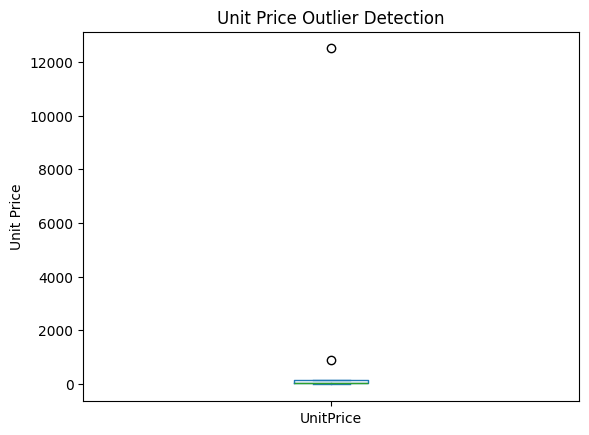

In [35]:
df["UnitPrice"].dropna().plot(
    kind="box",
    title="Unit Price Outlier Detection",
    ylabel="Unit Price"
)

In [36]:
df.loc[df["UnitPrice"] < 0, "UnitPrice"] = np.nan

df.loc[df["ShippingFee"] < 0, "ShippingFee"] = np.nan

df["UnitPrice"] = df["UnitPrice"].fillna(df["UnitPrice"].median())

df["ShippingFee"] = df["ShippingFee"].fillna(df["ShippingFee"].median())

print(df[["UnitPrice", "ShippingFee"]].isnull().sum())

UnitPrice      0
ShippingFee    0
dtype: int64


In [38]:
df["TotalAmount"] = (
    df["Quantity"] * df["UnitPrice"]
    + df["ShippingFee"]
)

df[[
        "OrderID",
        "Quantity",
        "UnitPrice",
        "ShippingFee",
        "TotalAmount"
    ]]

,OrderID,Quantity,UnitPrice,ShippingFee,TotalAmount
0,O1001,2.0,25.50,4.99,55.99
1,O1002,1.0,145.00,12.00,157.00
2,O1003,5.0,6.50,3.50,36.00
3,O1004,2.0,32.00,5.00,69.00
4,O1005,3.0,25.50,4.99,81.49
5,O1006,2.0,145.00,12.00,302.00
6,O1007,1.0,49.99,4.50,54.49
7,O1008,NaN,18.00,3.00,NaN
8,O1009,1.0,899.00,20.00,919.00
9,O1010,4.0,32.00,3.50,131.50


In [40]:
def categorize_price(price):
    if pd.isna(price):
        return "Unknown"
    elif price < 50:
        return "Low"
    elif price < 200:
        return "Medium"
    else:
        return "High"

df["PriceCategory"] = df["UnitPrice"].apply(
    categorize_price
)

df[["Product", "UnitPrice", "PriceCategory"]]

,Product,UnitPrice,PriceCategory
0,Desk Lamp,25.50,Low
1,Office Chair,145.00,Medium
2,Notebook Set,6.50,Low
3,Monitor Stand,32.00,Low
4,Desk Lamp,25.50,Low
5,Office Chair,145.00,Medium
6,Keyboard,49.99,Low
7,Mouse,18.00,Low
8,Monitor,899.00,High
9,Notebook Set,32.00,Low


In [43]:
print(
    df.groupby("PriceCategory", observed=True)
      .agg(
          Product_Count=("Product", "count"),
          Average_Price=("UnitPrice", "mean"),
          Average_Order_Amount=("TotalAmount", "mean")
      )
)

               Product_Count  Average_Price  Average_Order_Amount
PriceCategory                                                    
High                       2    6699.500000           6722.000000
Low                       13      27.767692             66.994167
Medium                     4     145.000000            229.500000


In [45]:
expensive_products = df[df["UnitPrice"] >= 200]

expensive_products

,OrderID,CustomerName,Product,OrderDate,Quantity,UnitPrice,ShippingFee,Invalid_Date,Invalid_Quantity,Invalid_Price,TotalAmount,PriceCategory
8,O1009,Ivan Chen,Monitor,2026-01-11,1.0,899.0,20.0,False,False,False,919.0,High
15,O1015,Omar Khan,Premium Monitor,2026-01-17,1.0,12500.0,25.0,False,False,False,12525.0,High


In [47]:
df.sort_values(
        by="TotalAmount",
        ascending=False,
        na_position="last"
    )

,OrderID,CustomerName,Product,OrderDate,Quantity,UnitPrice,ShippingFee,Invalid_Date,Invalid_Quantity,Invalid_Price,TotalAmount,PriceCategory
15,O1015,Omar Khan,Premium Monitor,2026-01-17,1.0,12500.00,25.00,False,False,False,12525.00,High
8,O1009,Ivan Chen,Monitor,2026-01-11,1.0,899.00,20.00,False,False,False,919.00,High
18,O1018,Ravi Nair,Office Chair,2026-01-20,2.0,145.00,12.00,False,False,False,302.00,Medium
5,O1006,Fatima Noor,Office Chair,2026-01-08,2.0,145.00,12.00,False,False,False,302.00,Medium
11,O1012,Lina Joseph,Office Chair,2026-01-14,1.0,145.00,12.00,False,False,False,157.00,Medium
1,O1002,Bob Smith,Office Chair,2026-01-04,1.0,145.00,12.00,False,False,False,157.00,Medium
9,O1010,Jaya Reddy,Notebook Set,2026-01-12,4.0,32.00,3.50,False,False,True,131.50,Low
13,O1014,Nisha Paul,Keyboard,2026-01-16,2.0,49.99,4.50,False,False,False,104.48,Low
12,O1013,Mohan Iyer,Monitor Stand,2026-01-15,3.0,32.00,5.00,False,False,False,101.00,Low
16,O1016,Priya Menon,Mouse,2026-01-18,3.0,32.00,3.00,False,False,True,99.00,Low


In [48]:
print("Unique products:", df["Product"].nunique())
print(df["Product"].value_counts())

Unique products: 8
Product
Desk Lamp          4
Office Chair       4
Notebook Set       3
Monitor Stand      2
Keyboard           2
Mouse              2
Monitor            1
Premium Monitor    1
Name: count, dtype: int64


In [49]:
print("Final shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nInvalid dates:")
print(df["OrderDate"].isna().sum())

print("\nInvalid quantities:")
print((df["Quantity"].isna() | (df["Quantity"] <= 0)).sum())

print("\nInvalid prices:")
print((df["UnitPrice"] < 0).sum())

print("\nCalculated column check:")
print(
    df[["OrderID", "Quantity", "UnitPrice",
        "ShippingFee", "TotalAmount"]].head()
)

Final shape: (19, 12)

Missing values:
OrderID             0
CustomerName        0
Product             0
OrderDate           1
Quantity            1
UnitPrice           0
ShippingFee         0
Invalid_Date        0
Invalid_Quantity    0
Invalid_Price       0
TotalAmount         1
PriceCategory       0
dtype: int64

Duplicate rows:
0

Data types:
OrderID                     object
CustomerName                object
Product                     object
OrderDate           datetime64[ns]
Quantity                   float64
UnitPrice                  float64
ShippingFee                float64
Invalid_Date                  bool
Invalid_Quantity              bool
Invalid_Price                 bool
TotalAmount                float64
PriceCategory               object
dtype: object

Invalid dates:
1

Invalid quantities:
2

Invalid prices:
0

Calculated column check:
  OrderID  Quantity  UnitPrice  ShippingFee  TotalAmount
0   O1001       2.0       25.5         4.99        55.99
1   O1002       1.

In [50]:
print("Cleaned shape:", df.shape)

# Save the processed data
df.to_csv("cleaned_orders.csv", index=False)

# Save records requiring review
review_rows = df[
    df["Invalid_Date"] | df["Invalid_Quantity"]
]

review_rows.to_csv("orders_requiring_review.csv", index=False)

print("Cleaned dataset and review file saved.")

Cleaned shape: (19, 12)
Cleaned dataset and review file saved.
